In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob
import subprocess

In [2]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300055289/semibin

3300046450.sorted.bam_0_data_cov.csv  output_bins
contig_bins.tsv			      recluster_bins_info.tsv
data.csv			      SemiBinRun.log
data_split.csv			      semibin_umap_coords.npy


In [3]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300055289

3300046450.a.depth.txt	3300046450.a.fna      metabat
3300046450.a.faa	3300046450.a.map.txt  semibin


In [4]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/3300055289

3300046450.a.cf		    3300046450.faa.mms2.index
3300046450.a.euks.txt	    3300046450.faa.mms2lca
3300046450.a.phylodist.txt  3300046450.faa.mms2.tsv
3300046450.a.tiara.txt	    log_3300046450.a.tiara.txt
3300046450.faa.mms2.dbtype


In [5]:
! cat /gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/3300046450/3300046450.faa.mms2lca | grep "Eukaryota" | wc -l

46808


In [6]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/*/semibin/semibin_umap_coords.npy

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300046450/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300046451/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300046467/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300046532/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300047668/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300047669/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300055289/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300057241/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300059487/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060027/semibin/semibin_umap_coords.npy
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060270/semibin/semibin_umap_coords.npy

In [7]:
! ls /gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/33000*/bam/*.sorted.bam

/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300045738/bam/3300045738.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300046103/bam/3300046103.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300046450/bam/3300046450.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300046451/bam/3300046451.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300046467/bam/3300046467.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300046532/bam/3300046532.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300047668/bam/3300047668.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300047669/bam/3300047669.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300055289/bam/3300055289.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300057241/bam/3300057241.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300059487/bam/3300059487.sorted.bam
/gpfs/data/mock_lab/will/mosaic_tmp/bam_tmpdir/3300059831/bam/3300059831.sor

In [8]:
sample_id = "3300055289"

df_mmseqs = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{sample_id}/{sample_id}.faa.mms2lca",
    sep = '\t'
)

df_mmseqs.head()

,contig_id,taxid,superkingdom,lineage,taxon,name
0,Ga0535628_0717480,1236,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria,class,Gammaproteobacteria
1,Ga0535628_0634590,1236,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria,class,Gammaproteobacteria
2,Ga0535628_0602659,1236,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria,class,Gammaproteobacteria
3,Ga0535628_0121016,1236,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria,class,Gammaproteobacteria
4,Ga0535628_0496014,1236,Bacteria,Bacteria;Pseudomonadota;Gammaproteobacteria,class,Gammaproteobacteria


In [9]:
df_umap_coords = pd.DataFrame(
    columns = ['umap_0', 'umap_1'],
    data = np.load(f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/semibin/semibin_umap_coords.npy")
)

df_umap_coords['sample'] = sample_id
df_umap_coords.head()

,umap_0,umap_1,sample
0,12.182323,17.759161,3300055289
1,12.206907,17.785093,3300055289
2,11.992276,17.565968,3300055289
3,12.078128,17.654165,3300055289
4,-2.265363,12.030138,3300055289


In [10]:
df_umap_coords.shape

(25553, 3)

In [11]:
df_semibin = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/semibin/contig_bins.tsv",
    sep = '\t', 
    names = ['contig_id', 'semibin_id'], 
    skiprows = 1
)

df_semibin.head()

,contig_id,semibin_id
0,Ga0535628_0000001,0
1,Ga0535628_0000002,0
2,Ga0535628_0000003,0
3,Ga0535628_0000004,0
4,Ga0535628_0000005,1


In [12]:
df_tiara = pd.read_csv(f"/gpfs/data/mock_lab/will/mosaic_tmp/taxo_tmpdir/{sample_id}/{sample_id}.a.tiara.txt", 
    sep = '\t'
)

df_tiara.head()

,sequence_id,class_fst_stage,class_snd_stage
0,Ga0535628_0000001,bacteria,NaN
1,Ga0535628_0000002,bacteria,NaN
2,Ga0535628_0000003,bacteria,NaN
3,Ga0535628_0000004,bacteria,NaN
4,Ga0535628_0000005,bacteria,NaN


In [28]:
df = pd.merge(
    df_umap_coords, 
    df_semibin, 
    left_index = True, 
    right_index = True, 
    how = 'left'
)

df.shape

(25553, 5)

In [29]:
df = pd.merge(
    df, 
    df_tiara, 
    left_on = 'contig_id', 
    right_on = 'sequence_id', 
    how = 'left'
)

In [30]:
df = pd.merge(
    df, 
    df_mmseqs[['contig_id', 'name', 'superkingdom', 'lineage']], 
    on = 'contig_id', 
    how = 'left'
).fillna("None")

In [31]:
line = subprocess.check_output(
    f"grep -H '>' /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/metabat/* | tr -d '>'", 
    shell=True, text=True
)

mbins = [(x.split("/")[-1].split(":")[0], x.split("/")[-1].split(":")[1]) for x in line.split()]

df_metabat = pd.DataFrame(
    columns = ['metabat_id', 'contig_id'], 
    data = mbins
)

In [32]:
df = pd.merge(
    df, 
    df_metabat, 
    on = 'contig_id',
    how = 'left'
).fillna('None')


In [33]:
df['semibin_id'] = df.semibin_id.apply(lambda x: "semibin." + str(x))

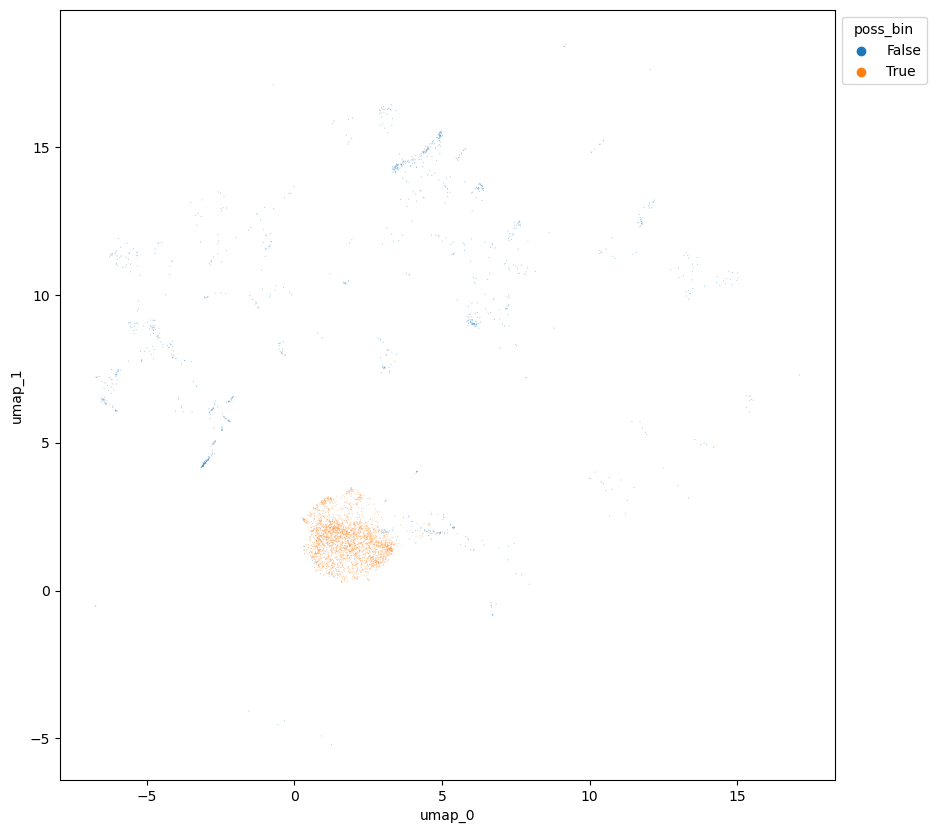

In [65]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df[
        ~df.superkingdom.isin(["None", "Unknown"])
    ], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.5, 
    alpha = 0.5, 
    hue = 'poss_bin'
)

sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [35]:
# Lots of euks
3300055289, 3300060027, 3300060270, 

(3300055289, 3300060027, 3300060270)

In [36]:
# Not working
3300059831, 3300060025, 3300060026, 3300069050, 3300069124, 

(3300059831, 3300060025, 3300060026, 3300069050, 3300069124)

In [37]:
sample_id

'3300055289'